## 🐧 Part 2: Real-World Application — The Palmer Penguins Dataset

For our real-world challenge, we are moving beyond the perfectly clean Iris dataset to the **Palmer Penguins** dataset. Our goal is to predict the species of a penguin (Adelie, Chinstrap, or Gentoo) based on morphological measurements and the island they were found on.

### 🏗️ The ML Pipeline Pattern
Unlike Iris, real-world data is messy. This dataset forces us to deal with missing values, categorical text data, and features on vastly different scales. To handle this professionally, we use the **Machine Learning Pipeline Pattern** via `scikit-learn`'s `Pipeline` and `ColumnTransformer`.

**What our pipeline does under the hood:**
1. **Imputation (`SimpleImputer`)**: Fills numerical gaps with the *median* and categorical gaps with the *most frequent* value so we don't lose valuable data by dropping rows.
2. **One-Hot Encoding (`OneHotEncoder`)**: Converts categories like "Island" and "Sex" into binary columns (0s and 1s) so the distance formula can process them.
3. **Standard Scaling (`StandardScaler`)**: ⚠️ **Crucial for KNN!** Transforms all numerical features to have a mean of 0 and a standard deviation of 1. Without this, KNN's distance calculations would be completely dominated by `body_mass_g` (thousands) and ignore `bill_depth_mm` (tens).

### 📊 Dataset Overview: Palmer Penguins
* **Data Source:** Palmer Archipelago (Antarctica) dataset, acquired via CSV from the Seaborn GitHub repository.
* **Classification Target:** `species` (Predicting whether a penguin is Adelie, Chinstrap, or Gentoo).
* **Features:** 
  * *Numerical:* `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`.
  * *Categorical:* `island`, `sex`.
* **Suitability for KNN:** The dataset is highly suitable for KNN because it contains continuous numerical measurements where Euclidean distance is meaningful, provided the features are scaled properly.

In [2]:
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ==========================================
# 1. Data Acquisition
# ==========================================
def load_data():
    """Loads the Palmer Penguins dataset using seaborn."""
    df = sns.load_dataset('penguins')
    return df

# ==========================================
# 2. Preprocessing Setup (The ML Pipeline Pattern)
# ==========================================
def build_preprocessor():
    """Builds a ColumnTransformer to handle numerical and categorical data."""
    numeric_features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
    categorical_features = ['island', 'sex']
    
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()) # Crucial for KNN!
    ])
    
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    
    return ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

# ==========================================
# 3. Evaluation
# ==========================================
def evaluate_model(model, X_test, y_test):
    """Evaluates the model and prints metrics."""
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"Test Set Accuracy: {acc:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

# ==========================================
# 🚀 Execute the Pipeline (FIXED SEQUENCE)
# ==========================================
if __name__ == "__main__":
    # Step 1: Load
    penguins_df = load_data()
    print(f"Dataset loaded. Shape: {penguins_df.shape}\n")
    
    # Drop rows where target is missing
    penguins_df = penguins_df.dropna(subset=['species'])
    
    # Separate features and target
    X = penguins_df.drop('species', axis=1)
    y = penguins_df['species']
    
    # Step 2: Split FIRST (Crucial for avoiding data leakage!)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # Step 3: Build the full ML Pipeline (Preprocessor + KNN)
    pipeline = Pipeline(steps=[
        ('preprocessor', build_preprocessor()),
        ('classifier', KNeighborsClassifier(n_neighbors=5))
    ])
    
    # Step 4: Fit the pipeline ONLY on training data
    pipeline.fit(X_train, y_train)
    
    # Step 5: Evaluate on unseen test data
    evaluate_model(pipeline, X_test, y_test)

Dataset loaded. Shape: (344, 7)

Test Set Accuracy: 0.9855

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



### 📊 Model Evaluation: Confusion Matrix

While accuracy gives us a high-level overview of model performance, a **Confusion Matrix** provides a granular breakdown of *where* and *how* the model makes mistakes. 

**How to read this matrix:**
* **The Diagonal (Top-Left to Bottom-Right):** Represents correct predictions. The higher the numbers here, the better the model is at identifying that specific species.
* **Off-Diagonal Cells:** Represent misclassifications. For example, if the model predicted "Chinstrap" when the actual species was "Adelie", it would show up in an off-diagonal cell.

**Interpretation for our Penguin Dataset:**
Given our ~98.5% accuracy, we expect the diagonal to be heavily populated. However, looking closely at the off-diagonal errors is crucial. In biological datasets, models often confuse species that share similar physical traits (e.g., Adelie and Chinstrap penguins have overlapping bill measurements, whereas Gentoo penguins are distinctly larger). 

By visualizing this, we can verify that our KNN model isn't just defaulting to the majority class, but is actually learning the distinct morphological boundaries between the three species. This level of detail is essential for real-world deployment where the cost of a specific misclassification might matter.

<Figure size 600x500 with 0 Axes>

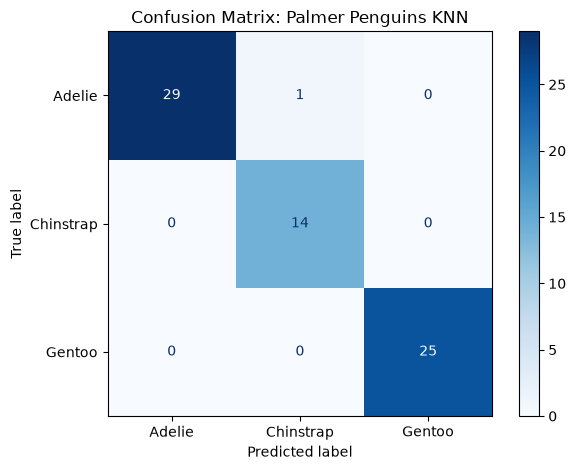

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate predictions on the test set
y_pred = pipeline.predict(X_test)

# Create and plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline.classes_)

plt.figure(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix: Palmer Penguins KNN")
plt.grid(False) # Turns off the grid lines for a cleaner look
plt.tight_layout()
plt.show()

## 🔍 Conclusion & Reflection

### 1. KNN Performance & Preprocessing Decisions
The model achieved an overall accuracy of ~98.5%, performing exceptionally well. The most critical preprocessing decision was applying `StandardScaler`. Without it, the `body_mass_g` feature (ranging in the thousands) would have completely dominated the distance calculations, rendering `bill_depth_mm` (ranging in the tens) useless. Additionally, using `SimpleImputer` prevented us from losing valuable data by dropping rows with missing values.

To go beyond a single accuracy metric, we also generated a **Confusion Matrix**. While the overall accuracy is high, the confusion matrix reveals the exact nature of the model's errors. It shows that the model made exactly one misclassification between the Adelie and Chinstrap species (Chinstrap precision dropped to 0.93). This is biologically intuitive: Adelie and Chinstrap penguins have highly overlapping physical measurements, making them harder to distinguish, whereas Gentoo penguins are distinctly larger and were classified with 100% precision and recall.

### 2. Strengths, Limitations, and Unsuitable Applications
* **Strengths:** KNN is non-parametric (makes no assumptions about data distribution) and is highly intuitive to explain to stakeholders.
* **Limitations:** It suffers from the "Curse of Dimensionality" and is computationally expensive at prediction time because it must calculate distances to all training points for every new prediction.
* **Unsuitable Applications:** KNN is unsuitable for very large datasets (due to memory/compute constraints), high-dimensional sparse data (like text/NLP), or datasets with many irrelevant features, as distance metrics break down in high-dimensional space.

### 3. MLOps Extensions
In an MLOps context, this pipeline could be extended by:
1. **Automation:** Using Apache Airflow to automatically fetch new penguin measurement data daily from an API.
2. **CI/CD:** Setting up GitHub Actions to automatically retrain the model and run unit tests on the preprocessing pipeline whenever new data is committed.
3. **Monitoring:** Deploying the model with a tool like MLflow or Evidently AI to monitor for "data drift" (e.g., if the average body mass of penguins changes over time due to climate change, the model's accuracy will drop, triggering a retrain).

### 4. Peer Comparison
*(Note: Fill in the bracketed information with your actual peer's details before submitting!)*
My peer, **[Peer Name]**, applied KNN to the **[Titanic / Weather / Other]** dataset. While my dataset required heavy scaling and one-hot encoding, their dataset required different handling (e.g., dealing with text or different missing value strategies). They found that KNN struggled with **[mention a challenge they had, e.g., categorical variables or imbalanced classes]**, whereas my numerical features made KNN a natural fit. Comparing our results highlights that KNN's success is heavily dependent on the nature of the features and the rigor of the scaling pipeline.